# Mesh fusion: CatBoost + PointNet++

## 1. Библиотеки

In [1]:
%pip install -q catboost iterative-stratification


Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from catboost import CatBoostClassifier
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from sklearn.metrics import f1_score

ROOT = Path('.')
TRAIN_DIR = ROOT / 'data' / 'train'
ARTIFACTS_DIR = ROOT / 'artifacts'

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)


## 2. Данные и split

In [3]:
train = pd.read_csv(ROOT / 'data' / 'train.csv')
target_columns = train.columns.drop('item_id').tolist()

mesh_features = pd.read_csv(
    ARTIFACTS_DIR / 'train_mesh_features.csv'
)

data = train.merge(
    mesh_features,
    on='item_id',
    how='inner',
    validate='one_to_one'
)

feature_columns = [
    column
    for column in mesh_features.columns
    if column != 'item_id'
]

data[feature_columns] = (
    data[feature_columns]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

splitter = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_val_index, test_index = next(
    splitter.split(data, data[target_columns])
)

train_val_df = data.iloc[train_val_index].reset_index(drop=True)
test_df = data.iloc[test_index].reset_index(drop=True)

splitter = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.1765,
    random_state=43
)

train_index, val_index = next(
    splitter.split(
        train_val_df,
        train_val_df[target_columns]
    )
)

val_df = train_val_df.iloc[val_index].reset_index(drop=True)
X_val = val_df[feature_columns]
val_targets = val_df[target_columns].to_numpy()

print('Validation:', len(val_df))
print('Internal test:', len(test_df))


Validation: 1361
Internal test: 1344


## 3. CatBoost ensemble

In [4]:
def load_catboost_probabilities(model_dir):
    probabilities = np.zeros(
        (len(val_df), len(target_columns))
    )

    for column_index, target in enumerate(target_columns):
        model = CatBoostClassifier()
        model.load_model(str(model_dir / f'{target}.cbm'))
        probabilities[:, column_index] = (
            model.predict_proba(X_val)[:, 1]
        )

    return probabilities


baseline_catboost_probabilities = load_catboost_probabilities(
    ROOT / 'models' / 'catboost'
)
depth_5_probabilities = load_catboost_probabilities(
    ROOT / 'models' / 'catboost_ensemble' / 'depth_5'
)
depth_7_probabilities = load_catboost_probabilities(
    ROOT / 'models' / 'catboost_ensemble' / 'depth_7'
)

catboost_probabilities = (
    0.8 * baseline_catboost_probabilities
    + 0.1 * depth_5_probabilities
    + 0.1 * depth_7_probabilities
)

print('CatBoost probabilities:', catboost_probabilities.shape)


CatBoost probabilities: (1361, 11)


## 4. PointNet++

In [5]:
NUM_POINTS = 512
BATCH_SIZE = 16


class PointCloudDataset(Dataset):
    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        with np.load(TRAIN_DIR / f"{row['item_id']}.npz") as mesh:
            points = mesh['vertices'].astype(np.float32)

        generator = np.random.default_rng(SEED + index)
        point_indices = generator.choice(
            len(points),
            NUM_POINTS,
            replace=len(points) < NUM_POINTS
        )

        points = points[point_indices]
        points = points - points.mean(axis=0)
        points = points / (
            np.linalg.norm(points, axis=1).max() + 1e-8
        )

        return torch.tensor(points, dtype=torch.float32)


def take_points(points, indices):
    batch = torch.arange(points.size(0), device=points.device)
    batch = batch.view(points.size(0), *([1] * (indices.dim() - 1)))
    return points[batch, indices]


def farthest_points(xyz, count):
    batch_size, point_count, _ = xyz.shape
    selected = torch.zeros(
        batch_size,
        count,
        dtype=torch.long,
        device=xyz.device
    )
    distances = torch.full(
        (batch_size, point_count),
        1e10,
        device=xyz.device
    )

    center = xyz.mean(dim=1, keepdim=True)
    farthest = ((xyz - center) ** 2).sum(-1).argmax(-1)
    batch = torch.arange(batch_size, device=xyz.device)

    for index in range(count):
        selected[:, index] = farthest
        point = xyz[batch, farthest].unsqueeze(1)
        distance = ((xyz - point) ** 2).sum(-1)
        distances = torch.minimum(distances, distance)
        farthest = distances.argmax(-1)

    return selected


def nearest_points(xyz, centers, count):
    distances = torch.cdist(centers, xyz)
    return distances.topk(count, largest=False).indices


In [6]:
class SetAbstraction(nn.Module):
    def __init__(self, center_count, neighbor_count, input_size, output_sizes):
        super().__init__()

        self.center_count = center_count
        self.neighbor_count = neighbor_count
        layers = []

        for output_size in output_sizes:
            layers += [
                nn.Conv2d(input_size, output_size, 1),
                nn.BatchNorm2d(output_size),
                nn.ReLU()
            ]
            input_size = output_size

        self.mlp = nn.Sequential(*layers)

    def forward(self, xyz, features=None):
        center_indices = farthest_points(xyz, self.center_count)
        centers = take_points(xyz, center_indices)
        neighbor_indices = nearest_points(
            xyz,
            centers,
            self.neighbor_count
        )

        local_xyz = take_points(xyz, neighbor_indices)
        local_xyz = local_xyz - centers.unsqueeze(2)

        if features is None:
            local_features = local_xyz
        else:
            local_features = torch.cat([
                local_xyz,
                take_points(features, neighbor_indices)
            ], dim=-1)

        local_features = local_features.permute(0, 3, 1, 2)
        new_features = self.mlp(local_features).max(dim=-1).values

        return centers, new_features.permute(0, 2, 1)


class SimplePointNetPlusPlus(nn.Module):
    def __init__(self, output_size):
        super().__init__()

        self.layer1 = SetAbstraction(128, 32, 3, [64, 128])
        self.layer2 = SetAbstraction(32, 32, 131, [128, 256])

        self.global_layer = nn.Sequential(
            nn.Conv1d(259, 512, 1),
            nn.ReLU(),
            nn.Conv1d(512, 1024, 1),
            nn.ReLU()
        )

        self.classifier = nn.Sequential(
            nn.Linear(1024, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, output_size)
        )

    def forward(self, points):
        xyz, features = self.layer1(points)
        xyz, features = self.layer2(xyz, features)

        features = torch.cat([xyz, features], dim=-1)
        features = features.permute(0, 2, 1)
        features = self.global_layer(features).max(dim=-1).values

        return self.classifier(features)


In [7]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

pointnet_model = SimplePointNetPlusPlus(
    len(target_columns)
).to(device)
pointnet_model.load_state_dict(
    torch.load(
        ROOT / 'models' / 'pointnetpp' / 'best_pointnetpp.pth',
        map_location=device,
        weights_only=True
    )
)
pointnet_model.eval()

val_dataset = PointCloudDataset(val_df)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print('Device:', device)


Device: cpu


In [8]:
pointnet_probabilities = []

with torch.no_grad():
    for points in val_loader:
        points = points.to(device)
        logits = pointnet_model(points)
        probabilities = torch.sigmoid(logits).cpu().numpy()
        pointnet_probabilities.append(probabilities)

pointnet_probabilities = np.concatenate(pointnet_probabilities)

print('PointNet++ probabilities:', pointnet_probabilities.shape)


PointNet++ probabilities: (1361, 11)


## 5. Метрики и fusion

In [9]:
def calculate_metrics(targets, probabilities, thresholds):
    predictions = (probabilities >= thresholds).astype(int)

    class_f1 = f1_score(
        targets,
        predictions,
        average=None,
        zero_division=0
    )
    weighted_f1 = f1_score(
        targets[:, :10],
        predictions[:, :10],
        average='weighted',
        zero_division=0
    )
    quality_f1 = class_f1[-1]

    return {
        'macro_f1': class_f1.mean(),
        'weighted_f1': weighted_f1,
        'quality_f1': quality_f1,
        'score': (weighted_f1 + quality_f1) / 2
    }


def find_best_thresholds(probabilities):
    threshold_grid = np.arange(0.05, 0.96, 0.01)
    thresholds = []

    for column_index in range(len(target_columns)):
        scores = [
            f1_score(
                val_targets[:, column_index],
                probabilities[:, column_index] >= threshold,
                zero_division=0
            )
            for threshold in threshold_grid
        ]
        thresholds.append(threshold_grid[np.argmax(scores)])

    return np.array(thresholds)


In [10]:
weight_grid = np.arange(0, 1.01, 0.05)
fusion_rows = []

for catboost_weight in weight_grid:
    probabilities = (
        catboost_weight * catboost_probabilities
        + (1 - catboost_weight) * pointnet_probabilities
    )
    thresholds = find_best_thresholds(probabilities)
    metrics = calculate_metrics(
        val_targets,
        probabilities,
        thresholds
    )

    fusion_rows.append({
        'catboost_weight': catboost_weight,
        **metrics
    })

fusion_results = pd.DataFrame(fusion_rows)
fusion_results.round(4)


,catboost_weight,macro_f1,weighted_f1,quality_f1,score
0,0.00,0.2988,0.4443,0.3260,0.3852
1,0.05,0.3207,0.4669,0.4063,0.4366
2,0.10,0.3370,0.4834,0.4620,0.4727
3,0.15,0.3502,0.4999,0.4890,0.4945
4,0.20,0.3630,0.5154,0.5066,0.5110
5,0.25,0.3729,0.5295,0.5106,0.5200
6,0.30,0.3849,0.5435,0.5153,0.5294
7,0.35,0.3919,0.5519,0.5105,0.5312
8,0.40,0.3940,0.5565,0.5118,0.5341
9,0.45,0.3959,0.5611,0.5155,0.5383


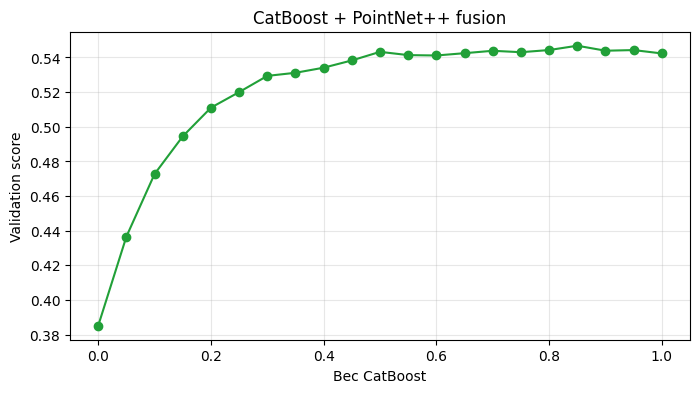

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(
    fusion_results['catboost_weight'],
    fusion_results['score'],
    marker='o',
    color='#21A038'
)
plt.xlabel('Вес CatBoost')
plt.ylabel('Validation score')
plt.title('CatBoost + PointNet++ fusion')
plt.grid(alpha=0.3)
plt.show()


In [12]:
best_row = fusion_results.loc[
    fusion_results['score'].idxmax()
]
best_catboost_weight = best_row['catboost_weight']

best_fusion_probabilities = (
    best_catboost_weight * catboost_probabilities
    + (1 - best_catboost_weight) * pointnet_probabilities
)
best_fusion_thresholds = find_best_thresholds(
    best_fusion_probabilities
)
best_fusion_metrics = calculate_metrics(
    val_targets,
    best_fusion_probabilities,
    best_fusion_thresholds
)

catboost_thresholds = find_best_thresholds(catboost_probabilities)
pointnet_thresholds = find_best_thresholds(pointnet_probabilities)

comparison = pd.DataFrame({
    'variant': [
        'CatBoost ensemble',
        'PointNet++',
        'CatBoost + PointNet++'
    ],
    'macro_f1': [
        calculate_metrics(
            val_targets,
            catboost_probabilities,
            catboost_thresholds
        )['macro_f1'],
        calculate_metrics(
            val_targets,
            pointnet_probabilities,
            pointnet_thresholds
        )['macro_f1'],
        best_fusion_metrics['macro_f1']
    ],
    'weighted_f1': [
        calculate_metrics(
            val_targets,
            catboost_probabilities,
            catboost_thresholds
        )['weighted_f1'],
        calculate_metrics(
            val_targets,
            pointnet_probabilities,
            pointnet_thresholds
        )['weighted_f1'],
        best_fusion_metrics['weighted_f1']
    ],
    'quality_f1': [
        calculate_metrics(
            val_targets,
            catboost_probabilities,
            catboost_thresholds
        )['quality_f1'],
        calculate_metrics(
            val_targets,
            pointnet_probabilities,
            pointnet_thresholds
        )['quality_f1'],
        best_fusion_metrics['quality_f1']
    ],
    'score': [
        calculate_metrics(
            val_targets,
            catboost_probabilities,
            catboost_thresholds
        )['score'],
        calculate_metrics(
            val_targets,
            pointnet_probabilities,
            pointnet_thresholds
        )['score'],
        best_fusion_metrics['score']
    ]
})

print('Лучший вес CatBoost:', round(best_catboost_weight, 2))
display(comparison.round(4))


Лучший вес CatBoost: 0.85


,variant,macro_f1,weighted_f1,quality_f1,score
0,CatBoost ensemble,0.4087,0.5634,0.5213,0.5423
1,PointNet++,0.2988,0.4443,0.3260,0.3852
2,CatBoost + PointNet++,0.4094,0.5683,0.5253,0.5468


In [13]:
FUSION_THRESHOLDS_PATH = (
    ARTIFACTS_DIR / 'catboost_pointnetpp_thresholds.json'
)

thresholds_to_save = {
    target: float(threshold)
    for target, threshold in zip(
        target_columns,
        best_fusion_thresholds
    )
}

with open(FUSION_THRESHOLDS_PATH, 'w', encoding='utf-8') as file:
    json.dump(thresholds_to_save, file, indent=2)

print('Сохранено:', FUSION_THRESHOLDS_PATH)


Сохранено: artifacts\catboost_pointnetpp_thresholds.json
